In [9]:
# Download data:

In [20]:
!mkdir -p data
!wget https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv -O data/tariff-distances-2022.csv

--2026-10-17 17:36:19--  https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv
Resolving opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)... 188.114.96.9, 188.114.97.9, 2a06:98c1:3120::9, ...
Connecting to opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)|188.114.96.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 583534 (570K) [application/octet-stream]
Saving to: ‘data/tariff-distances-2022.csv’

data/tariff-distanc 100%[===================>] 569.86K  1.12MB/s    in 0.5s    

2026-10-17 17:36:20 (1.12 MB/s) - ‘data/tariff-distances-2022.csv’ saved [583534/583534]



In [4]:
!wget https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv -O data/stations-2023.csv

--2026-10-17 17:18:10--  https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv
Resolving opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)... 188.114.97.9, 188.114.96.9, 2a06:98c1:3121::b, ...
Connecting to opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)|188.114.97.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 65007 (63K) [application/octet-stream]
Saving to: ‘data/stations-2023.csv’

data/stations-2023. 100%[===================>]  63.48K  --.-KB/s    in 0.1s    

2026-10-17 17:18:10 (629 KB/s) - ‘data/stations-2023.csv’ saved [65007/65007]



In [5]:
# I don't have much memory available so I downloaded only one yer per dataset
!wget https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-2023.csv -O data/disruptions.csv

--2026-10-17 17:21:51--  https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-2023.csv
Resolving opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)... 188.114.96.11, 188.114.97.11, 2a06:98c1:3121::b, ...
Connecting to opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)|188.114.96.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1632642 (1.6M) [application/octet-stream]
Saving to: ‘data/disruptions.csv’

data/disruptions.cs 100%[===================>]   1.56M  1.19MB/s    in 1.3s    

2026-10-17 17:21:53 (1.19 MB/s) - ‘data/disruptions.csv’ saved [1632642/1632642]



In [6]:
!wget https://opendata.rijdendetreinen.nl/public/services/services-2023.csv.gz -O data/services.csv.gz

--2026-10-17 17:22:39--  https://opendata.rijdendetreinen.nl/public/services/services-2023.csv.gz
Resolving opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)... 188.114.97.11, 188.114.96.11, 2a06:98c1:3121::b, ...
Connecting to opendata.rijdendetreinen.nl (opendata.rijdendetreinen.nl)|188.114.97.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 378407946 (361M) [application/octet-stream]
Saving to: ‘data/services.csv.gz’

data/services.csv.g 100%[===================>] 360.88M  36.8MB/s    in 12s     

2026-10-17 17:22:51 (30.9 MB/s) - ‘data/services.csv.gz’ saved [378407946/378407946]



In [7]:
import duckdb

con = duckdb.connect("data/duckdb_homework.db")

In [10]:
con

In [11]:
# Put stations data into stations table in DuckDB. This changes rarely, so we treat it as a almost constant file.

In [12]:
con.sql("""
CREATE TABLE IF NOT EXISTS stations AS
FROM 'data/stations-2023.csv'
""")

In [13]:
con.sql("DESCRIBE stations")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_long   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ slug        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ type        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lat     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lng     │ DOUB

In [14]:
# Based on DuckDB tutorial, create tables distances and distances_long. We treat this similarly to stations table.

In [25]:
con.sql("""
CREATE TABLE IF NOT EXISTS distances AS
FROM read_csv(
        'https://blobs.duckdb.org/data/tariff-distances-2022-01.csv',
        nullstr = 'XXX')
""")

In [26]:
con.sql("DESCRIBE distances")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Station     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ AC          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AH          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHP         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHPR        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHZ         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AKL         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AKM         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ALM         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ALMB        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│  ·          │   · 

In [30]:
con.sql("""
CREATE TABLE IF NOT EXISTS distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance
""")

In [31]:
con.sql("DESCRIBE distances_long")

┌───────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│  column_name  │ column_type │  null   │   key   │ default │  extra  │
│    varchar    │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Station       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ other_station │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ distance      │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
└───────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [32]:
# Put train disruptions into disruptions table in the Postgres database. We expect this data to change regularly, and thus treat it as a typical OLTP table.

In [35]:
con.sql("""INSTALL postgres; LOAD postgres;""")
conn_string = "host=localhost user=postgres password=postgres dbname=postgres"
con.sql(f"ATTACH IF NOT EXISTS '{conn_string}' AS pg (TYPE postgres)")

In [36]:
con.sql("""
CREATE TABLE IF NOT EXISTS pg.disruptions AS
SELECT * FROM read_csv('data/disruptions.csv')
""")
con.sql("SELECT COUNT(*) FROM pg.disruptions")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│         5168 │
└──────────────┘

In [49]:
con.sql("DESCRIBE pg.disruptions")

┌──────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│     column_name      │ column_type │  null   │   key   │ default │  extra  │
│       varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ rdt_id               │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ns_lines             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_lines            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_lines_id         │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_station_names    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_station_codes    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ cause_nl             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ cause_en             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ statistical_cause_nl │ VARCHAR     │ YES     │ NUL

In [16]:
# Transform train services CSV files into a single Parquet file. Make table services from it. We treat this as a big data batch input, created rarely but regularly for analytics purposes.

In [37]:
con.sql("""
COPY (SELECT * FROM read_csv('data/services.csv.gz')) TO 
'data/services.parquet' (FORMAT parquet, COMPRESSION ZSTD)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [38]:
con.sql("""
CREATE TABLE IF NOT EXISTS services AS
SELECT * FROM 'data/services.parquet'
""")
con.sql("DESCRIBE services")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────────────────────┬──────────────────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name          │       column_type        │  null   │   key   │ default │  extra  │
│           varchar            │         varchar          │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────────┼──────────────────────────┼─────────┼─────────┼─────────┼─────────┤
│ Service:RDT-ID               │ BIGINT                   │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Date                 │ DATE                     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Type                 │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Company              │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Train number         │ BIGINT                   │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Completely cancelled │ BOOLEAN                  │ YES     │ NULL    │ NULL    │ NULL    │


In [ ]:
# In all following questions, use tables services, distances_long, disruptions and stations as necessary. Remember that each row represents single ride between stations, while the whole end-to-end train service has the same value in Service:RDT-ID column. Note that starting station for a service has NULL value in Stop:Arrival time column, while the end station has NULL value in Stop:Departure time column.
# Make queries to answer the following questions:

In [40]:
# How many trains departed from Amsterdam Central station overall?

con.sql("""
SELECT COUNT(*) AS departures
FROM services
WHERE "Stop:Station code" = 'ASD'
AND "Stop:Departure time" IS NOT NULL
AND NOT COALESCE("Stop:Departure cancelled", false)
""")

┌────────────┐
│ departures │
│   int64    │
├────────────┤
│     245943 │
└────────────┘

In [51]:
# Calculate the average arrival delay of different service types (Service:Type). Order results descending by average delay.
con.sql("""
SELECT "Service:Type" AS service_type,
AVG(COALESCE("Stop:Arrival delay", 0)) AS avg_arrival_delay,
COUNT(*) AS n_arrivals
FROM services
WHERE "Stop:Arrival time" IS NOT NULL
GROUP BY 1
ORDER BY avg_arrival_delay DESC
""")

┌──────────────────────┬──────────────────────┬────────────┐
│     service_type     │  avg_arrival_delay   │ n_arrivals │
│       varchar        │        double        │   int64    │
├──────────────────────┼──────────────────────┼────────────┤
│ Stoomtrein           │   17.444444444444443 │          9 │
│ European Sleeper     │    9.844229217110573 │       1239 │
│ Nightjet             │    8.274968441375213 │      26934 │
│ ICE International    │   7.0675124365014605 │      37993 │
│ Eurostar             │    6.421771840933517 │      19539 │
│ Int. Trein           │    6.142857142857143 │         56 │
│ Thalys               │    5.902070574511519 │      34290 │
│ Nachttrein           │    4.156382079459003 │       1183 │
│ Intercity direct     │   3.0338565775150816 │     196594 │
│ Extra trein          │    2.853024342267027 │      16268 │
│      ·               │            ·         │         ·  │
│      ·               │            ·         │         ·  │
│      ·               │

In [50]:
# What was the most common disruption cause in different years? MODE function may be useful.
con.sql("""
SELECT year(start_time) AS year,
mode(statistical_cause_en) AS most_common_cause,
COUNT(*) AS n_disruptions
FROM pg.disruptions
GROUP BY 1 ORDER BY 1
""")

┌───────┬───────────────────┬───────────────┐
│ year  │ most_common_cause │ n_disruptions │
│ int64 │      varchar      │     int64     │
├───────┼───────────────────┼───────────────┤
│  2023 │ broken down train │          5168 │
└───────┴───────────────────┴───────────────┘

In [56]:
# How many trains started their overall service in any Amsterdam station?
con.sql("""
SELECT COUNT(DISTINCT s."Service:RDT-ID") AS services_started_in_amsterdam
FROM services s
JOIN stations st ON s."Stop:Station code" = st.code
WHERE s."Stop:Arrival time" IS NULL
AND st.name_long LIKE 'Amsterdam%'
""")

# RDT-ID is ID of one overall service

┌───────────────────────────────┐
│ services_started_in_amsterdam │
│             int64             │
├───────────────────────────────┤
│                        145953 │
└───────────────────────────────┘

In [58]:
# What fraction of services was run to final destinations outside the Netherlands?
con.sql("""
SELECT COUNT(*) AS total_services,
COUNT(*) FILTER (WHERE st.country <> 'NL') AS abroad,
abroad / total_services AS fraction_abroad
FROM services s
LEFT JOIN stations st ON s."Stop:Station code" = st.code
WHERE s."Stop:Departure time" IS NULL
""")

┌────────────────┬────────┬─────────────────────┐
│ total_services │ abroad │   fraction_abroad   │
│     int64      │ int64  │       double        │
├────────────────┼────────┼─────────────────────┤
│        2344963 │ 109069 │ 0.04651203451824187 │
└────────────────┴────────┴─────────────────────┘

In [61]:
# What is the largest distance between stations in the Netherlands (code NL)?
con.sql("""
SELECT MAX(d.distance) AS max_distance
FROM distances_long d
JOIN stations s1 ON d.Station = s1.code
JOIN stations s2 ON d.other_station = s2.code
WHERE s1.country = 'NL' 
  AND s2.country = 'NL'
""")

┌──────────────┐
│ max_distance │
│    int64     │
├──────────────┤
│          426 │
└──────────────┘

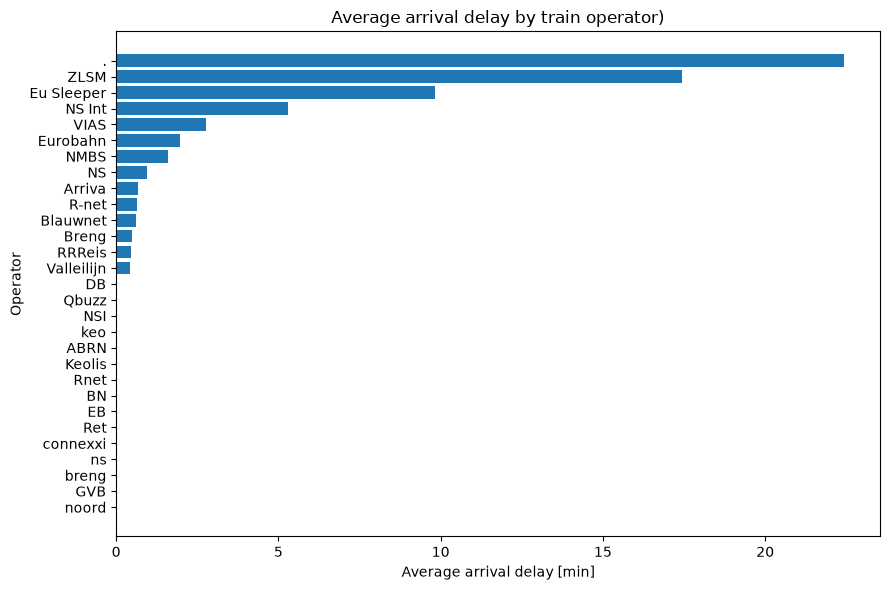

In [69]:
import matplotlib.pyplot as plt

# Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them appropriately.
df = con.sql("""
SELECT "Service:Company" as company,
AVG(COALESCE("Stop:Arrival delay", 0)) AS avg_arrival_delay,
COUNT(*) AS n_arrivals
FROM services
WHERE "Stop:Arrival time" IS NOT NULL
GROUP BY 1
ORDER BY avg_arrival_delay
""").df()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(df["company"], df["avg_arrival_delay"])
ax.set_title("Average arrival delay by train operator)")
ax.set_xlabel("Average arrival delay [min]")
ax.set_ylabel("Operator")
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Number of services')

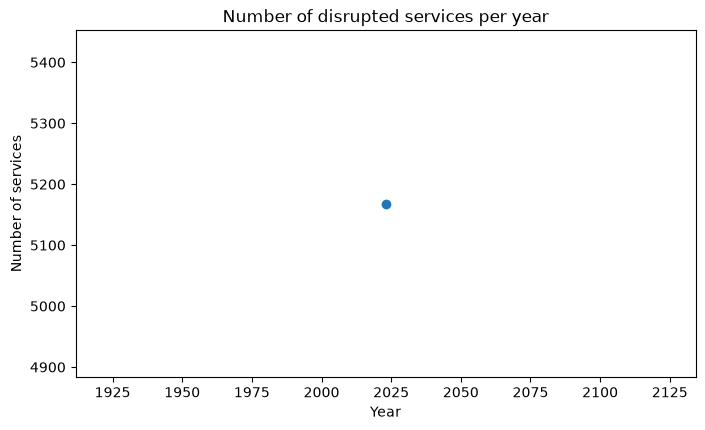

In [86]:
# How many services were disrupted in different years? Make a line plot.
df = con.sql("""
SELECT 
EXTRACT(YEAR FROM start_time) AS year, 
COUNT(*) AS disruptions_count
FROM pg.disruptions
GROUP BY year
ORDER BY year
""").df()

ax = df.plot.line(
    x="year", y="disruptions_count", marker="o", legend=False, figsize=(8, 4.5)
)
ax.set_title("Number of disrupted services per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of services")

# I've downloaded data for only one year, so on the plot there is only a dot, not a line

Text(0, 0.5, 'cancelled_fraction')

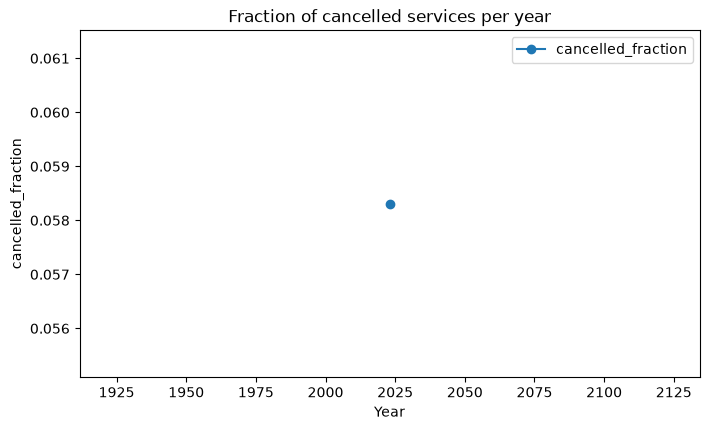

In [93]:
# What fraction of all services were cancelled (Service:Completely cancelled) in different years? Make a line plot.
df = con.sql("""
SELECT year("Service:Date") AS year,
AVG("Service:Completely cancelled"::INT) AS cancelled_fraction
FROM services
WHERE "Stop:Arrival time" IS NULL
GROUP BY 1 ORDER BY 1
""").df()

ax = df.plot.line(x="year", y="cancelled_fraction", marker="o", figsize=(8, 4.5))
ax.set_title("Fraction of cancelled services per year")
ax.set_xlabel("Year")
ax.set_ylabel("cancelled_fraction")

# I've downloaded data for only one year, so on the plot there is only a dot, not a line

In [ ]:
# Currently, services table does not provide information about service lengths, neither between pairs of stations nor for the end-to-end service. Prepare this information:
# Note that each service has the same Service:RDT-ID, and stations can be ordered by Stop:Departure time, with the last one being NULL. Using window functions, specifically LAG() or LEAD(), you can get next row. This example may also be useful.
# Create table station_connections, with columns Service:RDT-ID, start_station_code and end_station_code (pair of stations on a route), and distance between them. Note that you should deduplicate the data on station codes, so that every station pair appears only once. Create temporary tables, use a subquery, or any other similar techniques if necessary.


In [94]:
con.sql("""
CREATE TABLE IF NOT EXISTS station_connections AS
WITH segments AS (
    SELECT "Service:RDT-ID" AS service_id,
           "Stop:Station code" AS start_station_code,
           LEAD("Stop:Station code") OVER (
               PARTITION BY "Service:RDT-ID"
               ORDER BY "Stop:Departure time" NULLS LAST
           ) AS end_station_code
    FROM services
),
unique_pairs AS (
    SELECT start_station_code, end_station_code, MIN(service_id) AS service_id
    FROM segments
    WHERE end_station_code IS NOT NULL
    GROUP BY start_station_code, end_station_code
)
SELECT p.service_id AS "Service:RDT-ID",
       p.start_station_code,
       p.end_station_code,
       d.distance
FROM unique_pairs p
JOIN distances_long d
  ON d.Station = p.start_station_code AND d.other_station = p.end_station_code
""")

# this query was written with AI

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [95]:
# What is the largest distance between a pair of stations?
con.sql("""
SELECT c.start_station_code, s1.name_long AS start_station,
c.end_station_code, s2.name_long AS end_station, c.distance
FROM station_connections c
JOIN stations s1 ON c.start_station_code = s1.code
JOIN stations s2 ON c.end_station_code = s2.code
ORDER BY c.distance DESC
LIMIT 1
""")

┌────────────────────┬───────────────┬──────────────────┬─────────────┬──────────┐
│ start_station_code │ start_station │ end_station_code │ end_station │ distance │
│      varchar       │    varchar    │     varchar      │   varchar   │  int64   │
├────────────────────┼───────────────┼──────────────────┼─────────────┼──────────┤
│ ASN                │ Assen         │ VS               │ Vlissingen  │      353 │
└────────────────────┴───────────────┴──────────────────┴─────────────┴──────────┘

In [ ]:
# Plot a histogram of inter-station distances run by trains.

Text(0, 0.5, 'Number of station pairs')

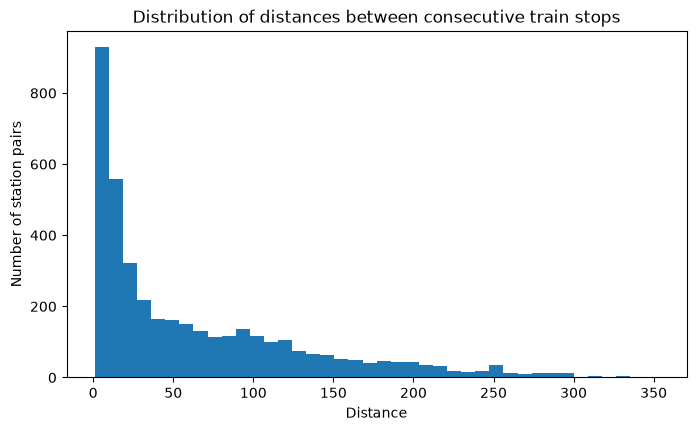

In [98]:
df = con.sql("SELECT distance FROM station_connections").df()

ax = df["distance"].plot.hist(bins=40, figsize=(8, 4.5))
ax.set_title("Distribution of distances between consecutive train stops")
ax.set_xlabel("Distance")
ax.set_ylabel("Number of station pairs")